In [7]:
from data_loader import load_dataset_cleaned
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

df = load_dataset_cleaned()
eda = df.copy()
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Study of Correlations between features

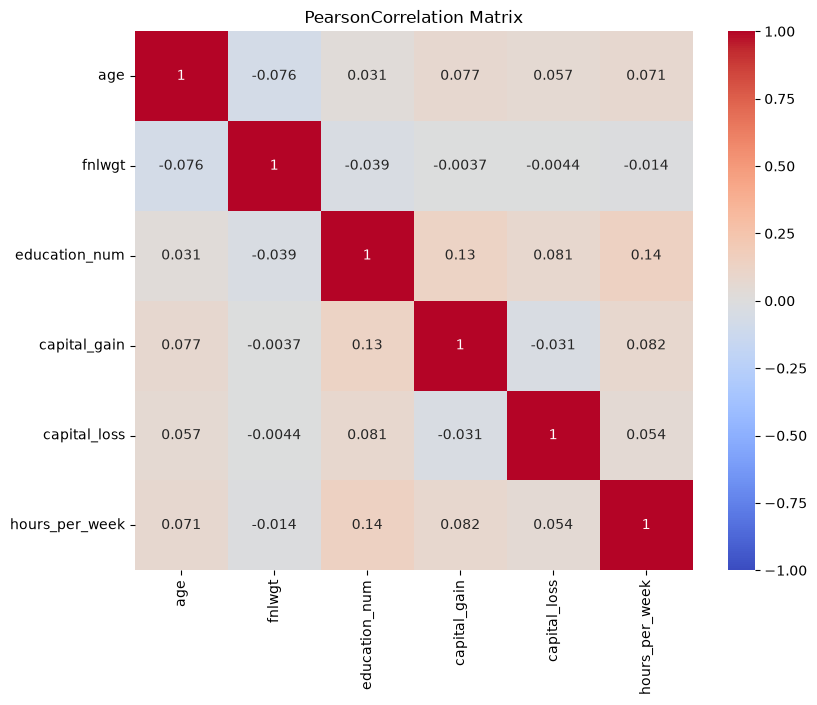

In [2]:
corr_cols = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
corr_matrix = eda[corr_cols].corr(method='pearson')

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,vmax=1,vmin=-1)
plt.title('PearsonCorrelation Matrix')
plt.show()

La matrice di Pearson indica una correlazione lineare debole tra capital_gain e education_num

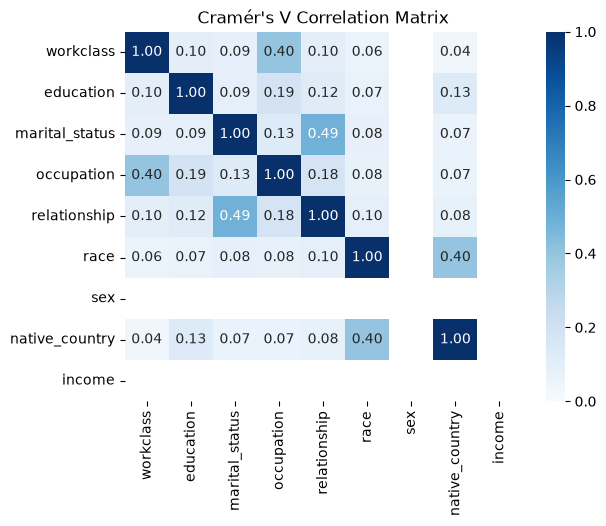

2

In [13]:
from scipy.stats import chi2_contingency

def cramers_v(x,y):
    table = pd.crosstab(x.fillna('Missing'),y.fillna('Missing'))
    if min(table.shape) <= 2:
        return np.nan
    
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

categorical_columns = df.select_dtypes(include=['object',"string"]).columns
matrix = pd.DataFrame(index=categorical_columns, columns=categorical_columns,dtype=float)
for col1 in categorical_columns:
    for col2 in categorical_columns:
        matrix.loc[col1, col2] = cramers_v(eda[col1], eda[col2])
        
sns.heatmap(matrix,annot=True,fmt=".2f",cmap='Blues',vmax=1,vmin=0)
plt.title("Cramér's V Correlation Matrix")
plt.show()
eda["sex"].nunique(dropna=False)

Ci sono relazioni moderate tra:
- race e native_country
- relationship e marital_status
- occupation e workclass